In [ ]:
from PIL import Image
from pylab import *
import numpy as np
import matplotlib.pyplot as plt
import math
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


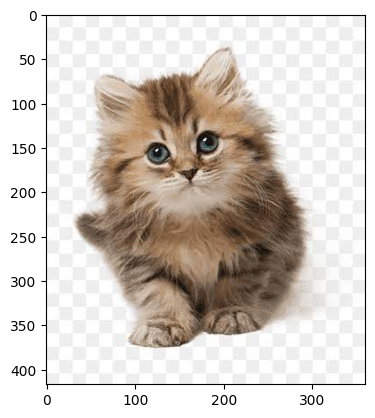

In [ ]:
import os
path = "/content/drive/MyDrive/Colab Notebooks/Bilgisayarla Görme"
im = np.array(Image.open(path+"/images/kedi.jpeg"))
im_gray = np.array(Image.open(path+"/images/kedi.jpeg").convert('L'))

imgplot = plt.imshow(im)
plt.show()

Resim Boyutu: (417, 360, 3)
Kırpılmış Resim Boyutu: (200, 200, 3)


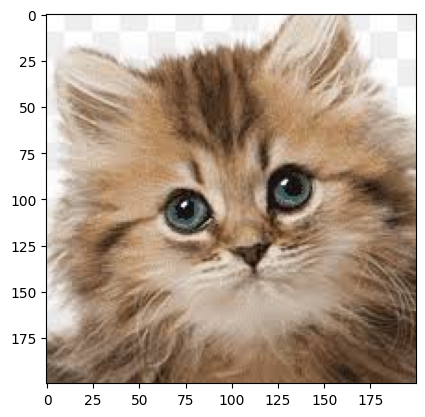

In [ ]:
def trim(array, x, y, width, height):
  return array[y:y + height, x:x + width]

# Resmin boyutlarını yazdıralım (yükseklik, genişlik, kanal)
print("Resim Boyutu:", im.shape)

# Resminizin gerçek boyutuna uygun koordinatlar tanımlıyoruz.
# Boyutlarına göre bu değerleri isteğinize göre güncelleyebilirsiniz.
y_loc = 50
x_loc = 50
width = 200
height = 200

im_trim = trim(im, x_loc, y_loc, width, height)
print("Kırpılmış Resim Boyutu:", im_trim.shape)

if im_trim.size > 0:
  imgplot = plt.imshow(im_trim)
  plt.show()
else:
  print("Hata: Kırpma alanı boş kaldı! Lütfen x_loc, y_loc, width ve height değerlerini kontrol edin.")

xx shape[0 1 2 3 4 5 6 7 8 9]yy shape:[0 0 0 0 0 0 0 0 0 0]


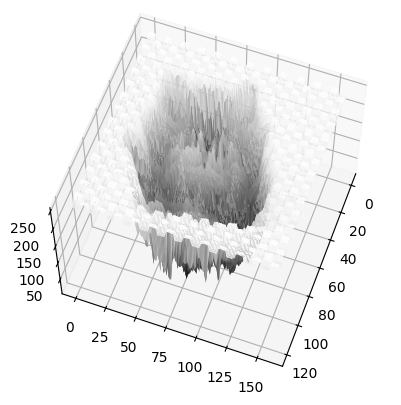

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

imcv_gray_rs = cv2.resize(imcv_gray, (160, 120))

# create grid to plot using numpy

xx, yy = np.mgrid[0:imcv_gray_rs.shape[0], 0:imcv_gray_rs.shape[1]]

print("xx shape" +str(xx[0:10,0]) + "yy shape:" +str(yy[0:10,0]) )

# create the figure

fig = plt.figure()
ax = fig.add_subplot(projection = '3d')
ax.plot_surface(xx, yy, imcv_gray_rs, rstride=1, cstride=1, cmap=plt.cm.gray, linewidth=1)
ax.view_init(elev=60, azim=20)
ax.dist=5
plt.show()

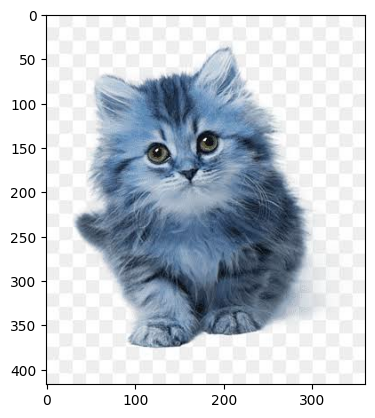

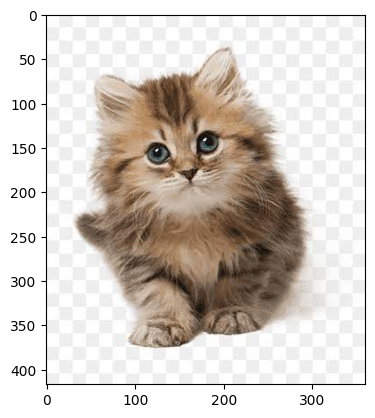

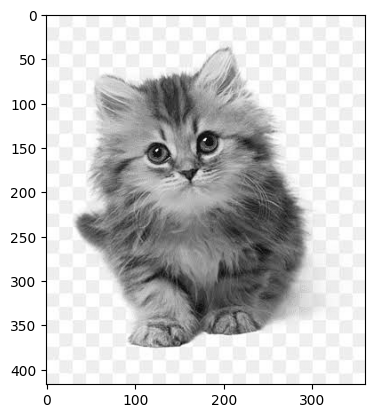

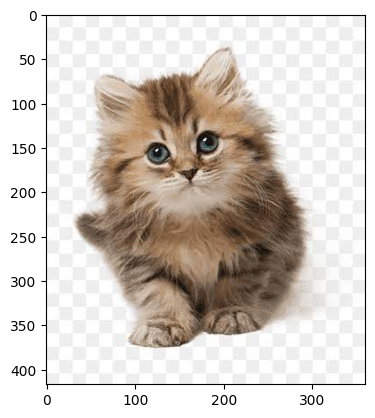

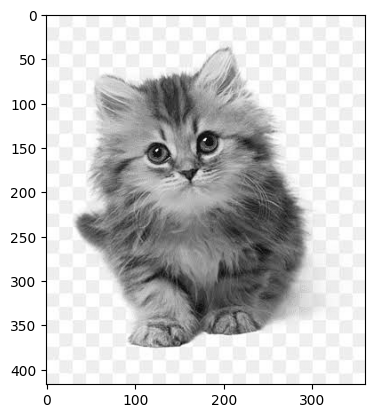

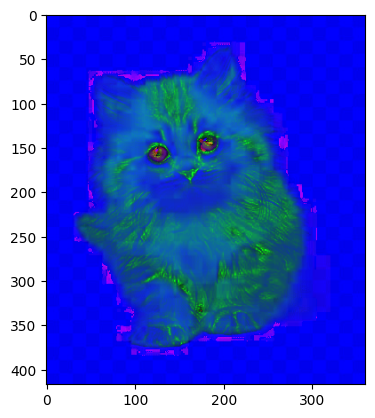

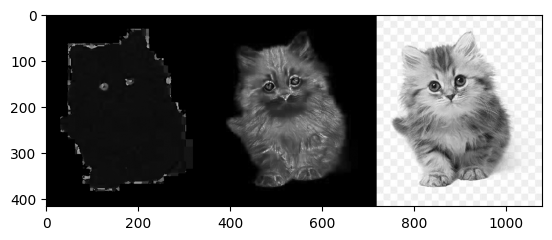

In [ ]:
import cv2
imcv = cv2.imread(path+"/images/kedi.jpeg")
imgplot = plt.imshow(imcv)
plt.show()

imcv_rgb = cv2.cvtColor(imcv, cv2. COLOR_BGR2RGB)
imgplot = plt.imshow(imcv_rgb)
plt.show()

imcv_gray = cv2.cvtColor(imcv, cv2.COLOR_BGR2GRAY)
imgplot = plt.imshow(imcv_gray, cmap='gray')
plt.show()

imcv_hsv = cv2.cvtColor(imcv, cv2. COLOR_BGR2HSV)

imcv_rgb = cv2.cvtColor(imcv, cv2.COLOR_BGR2RGB)
imgplot= plt.imshow(imcv_rgb)
plt.show()

imcv_gray = cv2.cvtColor(imcv, cv2.COLOR_BGR2GRAY)
imgplot = plt. imshow(imcv_gray, cmap='gray')
plt.show()

inc_hsv = cv2.cvtColor(imcv, cv2.COLOR_BGR2HSV)
imgplot = plt. imshow(imcv_hsv, cmap='hsv')
plt.show()

im_concat = np. concatenate((imcv_hsv[:,:,0], imcv_hsv[:,:,1], imcv_hsv[:,:,2]), axis=1)
imgplot =plt.imshow(im_concat, cmap='gray')
plt.show()

In [ ]:
def point_operation(img, a, b):
  img = np.float64(img)
  img = img* a + b
  img[img > 255] = 255
  img[img < 0] = 0
  return np.uint8(img)


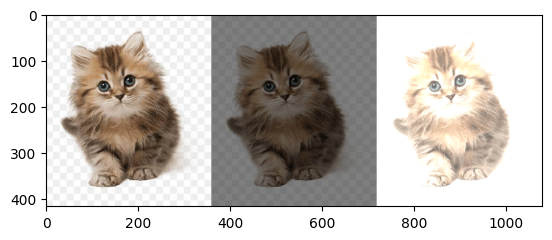

In [ ]:
a = 0.5
b = 0
out1 = point_operation(im, a, b)

a = 1.0
b = 100
out2 = point_operation(im, a, b)
res = np.concatenate((im, out1, out2), axis=1)
plt.imshow(res, cmap = 'gray')
plt.show()

data type: uint8
data type: float32
max intensity at all channels: 255.0
data type: float32
data type: uint8


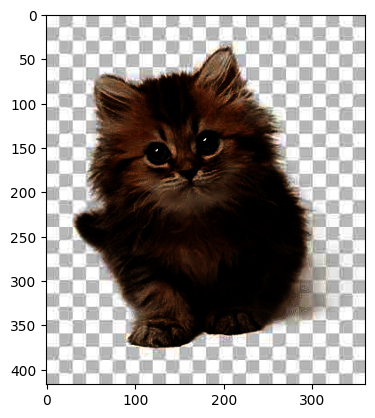

In [ ]:
gamma =5
im_f = np.float32(im)
print('data type: '+str(im.dtype))
print('data type: '+str(im_f.dtype))
print('max intensity at all channels: ' +str(im_f.max()))
im_gt = 255.0 * ((im_f/255.0)**gamma)
print('data type: ' +str(im_gt.dtype))
im_gt = np.uint8(im_gt)
print('data type: ' +str(im_gt.dtype))
imgplot = plt.imshow(im_gt, cmap ='gray')
plt.show()

bins[0..5]:[ 2.        5.953125  9.90625  13.859375 17.8125  ]


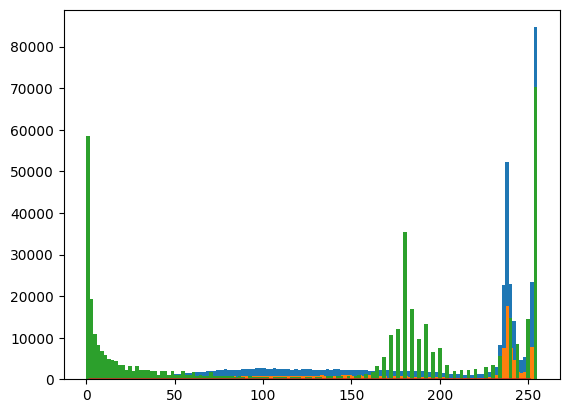

In [ ]:
hist(im.flatten(),128)
hist(im_gray.flatten(),128)
hist(im_gt.flatten(),128)
show
imhist,bins = histogram(im_gray.flatten(),64)
NumOfPixels = np.prod(im_gray.shape)
imhist= imhist/NumOfPixels
plt.plot(bins[:-1], imhist)
plt.show
print('bins[0..5]:' +str(bins[0:5]))

In [ ]:
def histeq(im, nbr_bins= 256):
  imhist, bins = histogram(im.flatten(), nbr_bins)
  cdf = imhist.cumsum()
  cdf = 255 * cdf / cdf[-1]
  im2 = interp(im.flatten(), bins[:-1], cdf)
  imhist_eq, bins =  histogram(im2.flatten(), nbr_bins)
  return im2.reshape(im.shape), imhist, cdf, imhist_eq

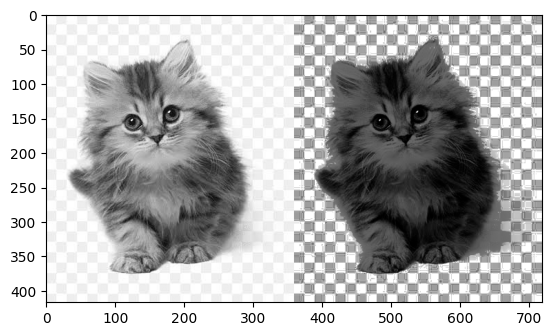

In [ ]:
im_eq, imhist, cdf, imhist_eq = histeq(im_gray)
im_list = np.concatenate((im_gray, im_eq), axis=1)
imgplot = plt.imshow(im_list, cmap ='gray')
plt.show()

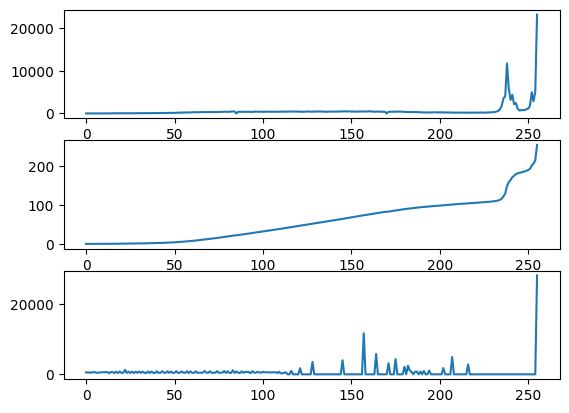

In [ ]:
fig, ax =plt.subplots(nrows=3 , ncols=1)
ax[0].plot(imhist)
ax[1].plot(cdf)
ax[2].plot(imhist_eq)
plt.show()